# Détection automatique des crises d'absence à partir de l'EEG
**Mini-projet de data mining — notebook final exécuté**

Nous classons des fenêtres EEG de 2 s en « crise » ou « hors crise », comparons
quatre classifieurs (arbre de décision, forêt aléatoire, KNN, SVM) et cinq façons
de traiter le déséquilibre, puis reconstruisons les épisodes de crise.

Deux jeux de caractéristiques sont évalués côte à côte : les **12 caractéristiques
de l'énoncé**, et un jeu **enrichi** motivé par l'analyse exploratoire (section 6).
La sélection se fait uniquement en validation interne ; le test réservé n'est lu
qu'une fois, à la fin.

| Sections | Contenu |
|---|---|
| 1–4 | données, contrôles, visualisation, annotations (Q1–Q4) |
| 5–6 | fenêtres, étiquettes, caractéristiques (Q5–Q11) |
| 7–9 | séparation, entraînement, évaluation, comparaison (Q12–Q13) |
| 10–11 | reconstruction des épisodes et analyse des erreurs (Q14) |
| 12 | améliorations mesurées et validation « un enregistrement exclu » |

## 1. Chargement des données
Les fonctions de calcul sont dans `src/eeg_project.py` ; leur code est affiché
dans le notebook là où il sert. Les entraînements sont mis en cache avec une
empreinte du code, des données, des partitions et des versions : `RETRAIN = True`
force leur recalcul.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'Annotations MAJ.xlsx').exists() and (path / 'src/eeg_project.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import eeg_presentation as presentation
from src import eeg_project as eeg
from src.eeg_source_validation import validate_exports

OUT = ROOT / 'artifacts/final'
FIGURES = OUT / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
RETRAIN = False
presentation.apply_style()
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda value: f'{value:.3f}')

In [2]:
cohort, events, audit, all_events, unannotated = eeg.load_annotations(ROOT)
audit.to_csv(OUT / 'cohort_audit.csv', index=False)
events.to_csv(OUT / 'annotations_seconds.csv', index=False)
display(audit.rename(columns={
    'record_id': 'Enregistrement', 'excel_row': 'Ligne Excel', 'included': 'Retenu',
    'reason': 'Décision', 'actual_events': 'Paires réelles', 'declared_events': 'Nombre déclaré',
    'count_mismatch': 'Écart de comptage', 'age': 'Âge', 'sex': 'Sexe', 'duration_s': 'Durée du tracé (s)'
}))
display(Markdown(f'**Cohorte retenue : {len(cohort)} enregistrements, {len(events)} crises.** '
                 f'Exports sans ligne dans le classeur mis à jour, non utilisés : {", ".join(unannotated)}.'))

,Enregistrement,Ligne Excel,Âge,Sexe,Nombre déclaré,Paires réelles,Durée du tracé (s),Retenu,Décision,Écart de comptage
0,190304A-E,2,17.000,M,1.000,1,1575.000,True,Retenu,False
1,191113A-D,3,25.000,F,2.000,2,1810.000,True,Retenu,False
2,210406A-F,4,8.000,F,1.000,1,1454.000,True,Retenu,False
3,210427B-C,5,11.000,M,1.000,1,1246.000,True,Retenu,False
4,210504B-C,6,11.000,M,12.000,12,3121.000,False,Crise 1 hors limites du signal,False
5,210914B-A,7,8.000,F,6.000,11,1205.000,True,Retenu,True
6,210928B-B,8,7.000,M,2.000,2,1344.000,True,Retenu,False
7,211027B-C,9,5.000,F,8.000,8,1255.000,True,Retenu,False
8,211104B-D,10,9.000,M,5.000,5,1210.000,True,Retenu,False
9,230406B-A,11,11.000,M,4.000,4,1225.000,False,Doublon conflictuel : aucune ligne choisie arb...,False


**Cohorte retenue : 16 enregistrements, 65 crises.** Exports sans ligne dans le classeur mis à jour, non utilisés : 200625A-F, 210204B-C, 210208B-G.

Trois exclusions, décidées avant tout apprentissage :
`230406B-A` et `230515B-G` apparaissent deux fois avec des annotations
contradictoires ; `210504B-C` contient une crise à 21 608 s dans un tracé de
3 121 s. `210914B-A` déclare `NombreCE = 6` mais décrit 11 paires : les 11 sont
conservées. Les colonnes mal orthographiées `DebutCE5` et `DebtCE11` sont reconnues
par leur numéro.

## 2. Exploration
**Q1.** Les `.mat` contiennent des objets MATLAB `timetable` (MCOS) que `scipy.io`
et `h5py` ne lisent pas. Les exports NPZ sont comparés **valeur par valeur** aux
cellules numériques des fichiers d'origine : échantillons, noms des canaux, temps.
La fréquence est mesurée à partir du nombre d'échantillons par bloc et de l'écart
entre les lignes temporelles, puis vérifiée sur l'axe développé.

In [3]:
validation = validate_exports(ROOT, cohort.record_id, OUT)
display(validation[['record_id', 'n_channels', 'n_samples', 'samples_per_time_row',
                    'time_step_s', 'fs_hz', 'duration_s', 'source_values_match',
                    'source_names_match', 'source_times_match']].rename(columns={
    'record_id': 'Enregistrement', 'n_channels': 'Canaux', 'n_samples': 'Échantillons',
    'samples_per_time_row': 'Échantillons/bloc', 'time_step_s': 'Pas des blocs (s)',
    'fs_hz': 'Fréquence mesurée (Hz)', 'duration_s': 'Durée (s)',
    'source_values_match': 'Valeurs conformes', 'source_names_match': 'Canaux conformes',
    'source_times_match': 'Temps conformes'
}))
DEMO = '190304A-E'
t_demo, signal_demo, fs_demo = eeg.load_trace(ROOT, DEMO, validation)
demo_intervals = list(events.loc[events.record_id == DEMO, ['start_s', 'end_s']]
                      .itertuples(index=False, name=None))
info = validation.set_index('record_id').loc[DEMO]
display(pd.Series({
    'Enregistrement': DEMO, 'Lignes': len(signal_demo), 'Variables (Time + canaux)': int(info.n_channels) + 1,
    'Fréquence mesurée (Hz)': fs_demo, 'Durée couverte (s)': len(signal_demo) / fs_demo,
    'Valeurs manquantes ou non finies': int((~np.isfinite(signal_demo)).sum())
}).to_frame('Q1'))
display(pd.DataFrame({'Time (s)': t_demo[:6], eeg.CHANNEL: signal_demo[:6]}))

Source vérifiée : 190304A-E


Source vérifiée : 191113A-D


Source vérifiée : 210406A-F


Source vérifiée : 210427B-C


Source vérifiée : 210914B-A


...

Source vérifiée : 230519A-E


Source vérifiée : 230718A-A


,Enregistrement,Canaux,Échantillons,Échantillons/bloc,Pas des blocs (s),Fréquence mesurée (Hz),Durée (s),Valeurs conformes,Canaux conformes,Temps conformes
0,190304A-E,23,403200,256,1.000,256.000,1575.000,True,True,True
1,191113A-D,23,463360,256,1.000,256.000,1810.000,True,True,True
2,210406A-F,23,372224,256,1.000,256.000,1454.000,True,True,True
3,210427B-C,21,318976,256,1.000,256.000,1246.000,True,True,True
4,210914B-A,21,308480,256,1.000,256.000,1205.000,True,True,True
5,210928B-B,21,344064,256,1.000,256.000,1344.000,True,True,True
6,211027B-C,21,321280,256,1.000,256.000,1255.000,True,True,True
7,211104B-D,21,309760,256,1.000,256.000,1210.000,True,True,True
8,220106A-A,23,312576,256,1.000,256.000,1221.000,True,True,True
9,220121B-D,21,330752,256,1.000,256.000,1292.000,True,True,True


,Q1
Enregistrement,190304A-E
Lignes,403200
Variables (Time + canaux),24
Fréquence mesurée (Hz),256.000
Durée couverte (s),1575.000
Valeurs manquantes ou non finies,0


,Time (s),EEGF7
0,0.000,0.038
1,0.004,0.038
2,0.008,0.038
3,0.012,0.038
4,0.016,0.038
5,0.020,0.038


Le canal **F7** (`EEGF7`), présent dans tous les tracés, est fixé avant toute
comparaison : les absences sont des crises généralisées, visibles sur l'ensemble
du scalp. Les amplitudes sont dans l'unité du fichier, qui n'est pas documentée.

## 3. Visualisations
**Q2.** Le tracé complet, puis un zoom de 10 s autour de la crise annotée.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


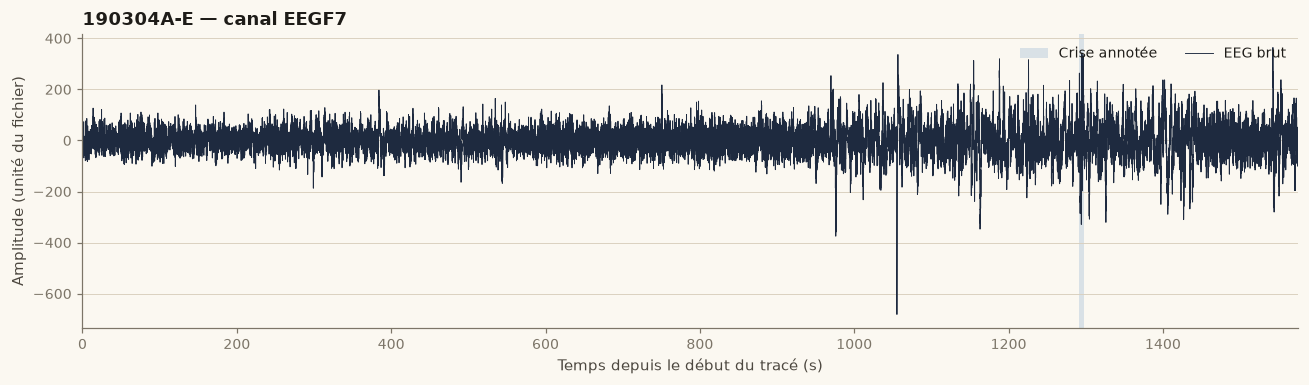

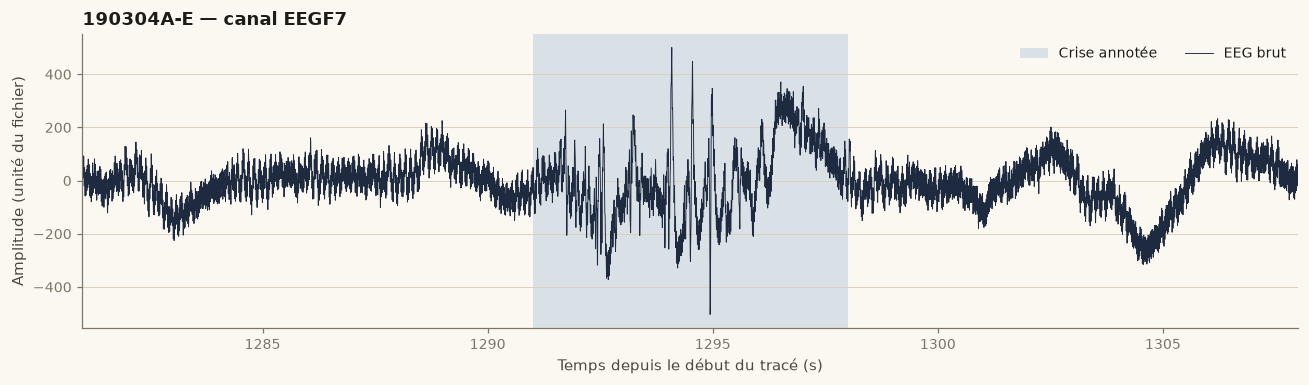

In [4]:
presentation.signal_plot(t_demo, signal_demo, demo_intervals, DEMO, FIGURES, name='signal_annote')
a, b = demo_intervals[0]
presentation.signal_plot(t_demo, signal_demo, demo_intervals, DEMO, FIGURES,
                         name='signal_zoom', bounds=(a - 10, b + 10))

Pendant l'intervalle annoté, le tracé montre une activité rythmique ample et
régulière, nettement différente de l'activité de fond. Le tracé complet montre aussi
une **dérive lente et un décalage continu** : le signal n'est pas centré sur zéro.
Ce point aura des conséquences en section 6.

## 4. Traitement des annotations
**Q3–Q4.** Les débuts et fins sont des **horaires Excel** (fractions de jour).
Ils sont convertis en secondes depuis le début du tracé :

`début_s = (DebCE − DebutTrace) × 86 400`, `fin_s = (FinCE − DebutTrace) × 86 400`.

Pour `190304A-E` : tracé commencé à 10:13:35, crise de 10:35:06 à 10:35:13,
soit **[1 291 s ; 1 298 s]** et une durée de **7 s**.

,Enregistrement,Crise,Début (s),Fin (s),Durée (s)
0,190304A-E,1,1291.000,1298.000,7.000
1,191113A-D,1,1254.000,1267.000,13.000
2,191113A-D,2,1428.000,1433.000,5.000
3,210406A-F,1,633.000,641.000,8.000
4,210427B-C,1,1031.000,1049.000,18.000
...,...,...,...,...,...
60,230718A-A,3,302.000,313.000,11.000
61,230718A-A,4,430.000,441.000,11.000
62,230718A-A,5,737.000,745.000,8.000
63,230718A-A,6,974.000,986.000,12.000


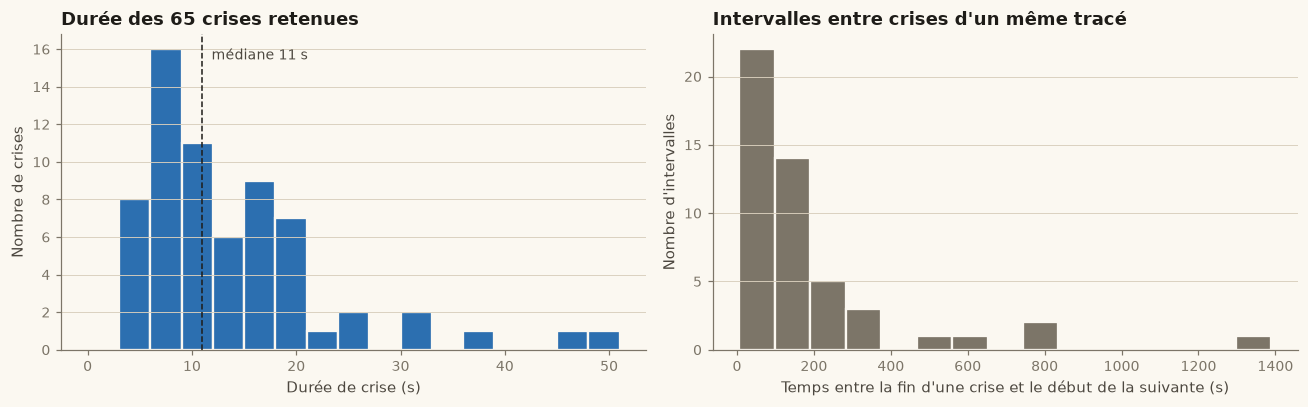

,Q4
Nombre de crises,65.000
Durée moyenne (s),13.462
Durée médiane (s),11.000
Durée minimale (s),3.000
Durée maximale (s),49.000
Intervalle moyen entre deux crises (s),185.857


In [5]:
display(events[['record_id', 'event', 'start_s', 'end_s', 'duration_s']]
        .rename(columns={'record_id': 'Enregistrement', 'event': 'Crise',
                         'start_s': 'Début (s)', 'end_s': 'Fin (s)', 'duration_s': 'Durée (s)'}))
gaps = presentation.duration_plots(events, FIGURES)
display(pd.Series({
    'Nombre de crises': len(events), 'Durée moyenne (s)': events.duration_s.mean(),
    'Durée médiane (s)': events.duration_s.median(), 'Durée minimale (s)': events.duration_s.min(),
    'Durée maximale (s)': events.duration_s.max(),
    'Intervalle moyen entre deux crises (s)': gaps.mean()
}).to_frame('Q4'))

Les durées ne sont pas identiques : de 3 à 49 s, avec une médiane de 11 s. Une
crise de 3 s ne couvre qu'une ou deux fenêtres de 2 s, alors qu'une crise de 49 s
en couvre une cinquantaine. La reconstruction des épisodes (section 10) doit en tenir compte.

## 5. Segmentation
**Q5–Q7.** Chaque échantillon reçoit la classe 1 s'il tombe dans un intervalle
annoté **[début, fin]** (bornes incluses, comme dans l'énoncé), 0 sinon. Les
fenêtres durent **2 s** (512 échantillons) avec un recouvrement de **50 %** (pas
de 256). Une fenêtre est de classe 1 si **au moins 50 %** de ses échantillons sont
en crise. Les tracés ne sont jamais concaténés.

In [6]:
presentation.show_source(eeg.sample_mask, eeg.segment_signal)

def sample_mask(time_values, intervals):
    """Applique l'intervalle fermé [début, fin], imprimé à la page 4 du PDF."""
    mask = np.zeros(len(time_values), dtype=bool)
    for start, end in intervals:
        mask |= (time_values >= start) & (time_values <= end)
    return mask

def segment_signal(time_values, signal, intervals, seconds=2.0, overlap=0.5):
    """Construit des fenêtres complètes et leur couverture réelle des crises."""
    fs = 1 / float(np.median(np.diff(time_values)))
    n = round(seconds * fs)
    hop = round(n * (1 - overlap))
    if n < 2 or hop < 1 or not 0 <= overlap < 1:
        raise ValueError("Paramètres de segmentation invalides.")
    starts = np.arange(0, len(signal) - n + 1, hop)
    windows = np.lib.stride_tricks.sliding_window_view(signal, n)[::hop]
    mask = sample_mask(time_values, intervals)
    cumulative = np.r_[0, np.cumsum(mask, dtype=np.int64)]
    coverage = (cumulative[starts + n] - cumulative[starts]) / n
    return windows, starts, (coverage >= 0.5).astype(np.int8), coverage, mask

In [7]:
demo_windows, demo_starts, demo_labels, demo_coverage, demo_mask = eeg.segment_signal(
    t_demo, signal_demo, demo_intervals)
display(pd.DataFrame({'Classe': ['Hors crise', 'Crise'],
                      'Échantillons': [int((~demo_mask).sum()), int(demo_mask.sum())],
                      'Fenêtres': [int((demo_labels == 0).sum()), int((demo_labels == 1).sum())]}))
display(pd.DataFrame({'Début fenêtre (s)': t_demo[demo_starts], 'Part de crise': demo_coverage,
                      'Class': demo_labels}).loc[demo_coverage > 0])

,Classe,Échantillons,Fenêtres
0,Hors crise,401407,1566
1,Crise,1793,8


,Début fenêtre (s),Part de crise,Class
1290,1290.000,0.500,1
1291,1291.000,1.000,1
1292,1292.000,1.000,1
1293,1293.000,1.000,1
1294,1294.000,1.000,1
1295,1295.000,1.000,1
1296,1296.000,1.000,1
1297,1297.000,0.502,1
1298,1298.000,0.002,0


La crise de 7 s produit 8 fenêtres positives. La fenêtre qui commence à 1 297 s
n'a que 50,2 % de ses échantillons en crise : elle est positive de justesse.

## 6. Extraction des caractéristiques
**Q8–Q11.** Une ligne par fenêtre. Les 12 prédicteurs demandés : moyenne,
écart-type, variance, minimum, maximum, amplitude (max − min), RMS, énergie (Σx²),
et les puissances FFT unilatérales en Delta [0,5 ; 4[, Theta [4 ; 8[, Alpha [8 ; 13[
et Beta [13 ; 30[ Hz.

In [8]:
presentation.show_source(eeg.one_sided_spectrum, eeg.extract_features)

def one_sided_spectrum(windows, fs):
    """Puissance FFT unilatérale |rFFT|²/N², doublée hors DC et Nyquist."""
    n = windows.shape[1]
    spectrum = np.abs(np.fft.rfft(windows, axis=1)) ** 2 / n**2
    scale = np.full(spectrum.shape[1], 2.0)
    scale[0] = 1
    if n % 2 == 0:
        scale[-1] = 1
    return spectrum * scale, np.fft.rfftfreq(n, d=1 / fs)

def extract_features(windows, fs):
    """Calcule les huit statistiques et les quatre puissances FFT unilatérales."""
    n = windows.shape[1]
    mean = windows.mean(axis=1)
    std = windows.std(axis=1)
    energy = (windows**2).sum(axis=1)
    lo, hi = windows.min(axis=1), windows.max(axis=1)
    values = np.column_stack((mean, std, std**2, lo, hi, hi - lo, np.sqrt(energy / n), energy))
    spectrum, frequencies = one_sided_spectrum(windows, fs)
    powers = [band_power(spectrum, frequencies, a, b) for a, b in BANDS.values()]
    return pd.DataFrame(np.column_stack((values, *powers)), columns=FEATURES)

,record_id,start_s,mean,std,variance,min,max,amplitude,rms,energy,power_delta,power_theta,power_alpha,power_beta,Class
0,190304A-E,0.000,-7.871,21.066,443.767,-107.141,73.340,180.481,22.488,258925.860,132.679,42.972,81.238,64.459,0
1,190304A-E,1.000,-21.837,29.018,842.026,-113.609,73.340,186.949,36.317,675275.160,144.354,79.035,187.186,129.990,0
2,190304A-E,2.000,-21.663,30.805,948.959,-113.609,61.944,175.553,37.660,726146.625,143.651,59.527,249.739,129.667,0
3,190304A-E,3.000,-11.172,38.843,1508.773,-117.690,121.617,239.307,40.418,836392.373,154.045,83.076,754.806,149.062,0
4,190304A-E,4.000,1.230,43.737,1912.963,-117.690,136.400,254.090,43.755,980212.270,201.892,193.174,952.496,186.593,0


,Enregistrement,Échantillons,Échantillons crise,Fenêtres,Fenêtres crise,Durée (s),Fréquence (Hz),Canal,Valeurs manquantes
0,190304A-E,403200,1793,1574,8,1575.000,256.000,EEGF7,0
1,191113A-D,463360,4610,1809,20,1810.000,256.000,EEGF7,0
2,210406A-F,372224,2049,1453,9,1454.000,256.000,EEGF7,0
3,210427B-C,318976,4609,1245,19,1246.000,256.000,EEGF7,0
4,210914B-A,308480,45067,1204,187,1205.000,256.000,EEGF7,0
5,210928B-B,344064,14082,1343,57,1344.000,256.000,EEGF7,0
6,211027B-C,321280,31496,1254,131,1255.000,256.000,EEGF7,0
7,211104B-D,309760,10245,1209,45,1210.000,256.000,EEGF7,0
8,220106A-A,312576,9474,1220,39,1221.000,256.000,EEGF7,0
9,220121B-D,330752,12803,1291,53,1292.000,256.000,EEGF7,0


**Cohorte :** 6,005,760 échantillons, dont 3.73 % en crise ; 23,444 fenêtres, dont 940 positives (4.01 %). Un classifieur qui répond toujours « hors crise » aurait donc environ 96 % d'accuracy.

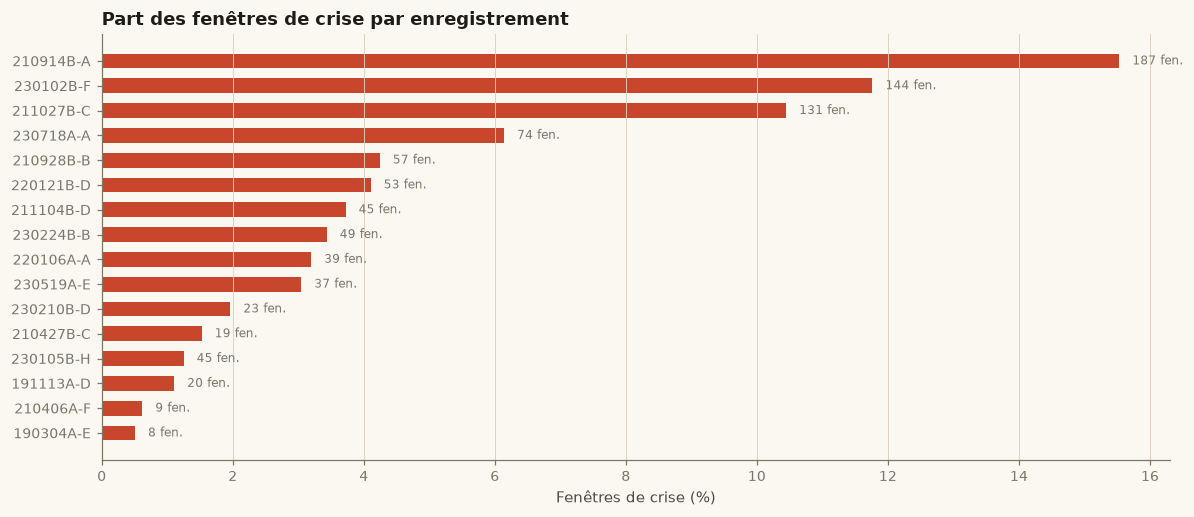

In [9]:
frame, counts = eeg.build_features(ROOT, cohort, events, validation)
frame.to_csv(OUT / 'features.csv', index=False)
counts.to_csv(OUT / 'class_counts.csv', index=False)
assert np.isfinite(frame[eeg.FEATURES + eeg.IMPROVED_FEATURES].to_numpy()).all()
display(frame[['record_id', 'start_s', *eeg.FEATURES, 'Class']].head(5))
display(counts.rename(columns={'record_id': 'Enregistrement', 'samples': 'Échantillons',
                               'positive_samples': 'Échantillons crise', 'windows': 'Fenêtres',
                               'positive_windows': 'Fenêtres crise', 'fs_hz': 'Fréquence (Hz)',
                               'duration_s': 'Durée (s)', 'channel': 'Canal',
                               'missing_values': 'Valeurs manquantes'}))
display(Markdown(
    f'**Cohorte :** {counts.samples.sum():,} échantillons, dont '
    f'{100 * counts.positive_samples.sum() / counts.samples.sum():.2f} % en crise ; '
    f'{len(frame):,} fenêtres, dont {int(frame.Class.sum())} positives ({100 * frame.Class.mean():.2f} %). '
    'Un classifieur qui répond toujours « hors crise » aurait donc environ 96 % d\'accuracy.'
))
presentation.imbalance_plot(counts, FIGURES)

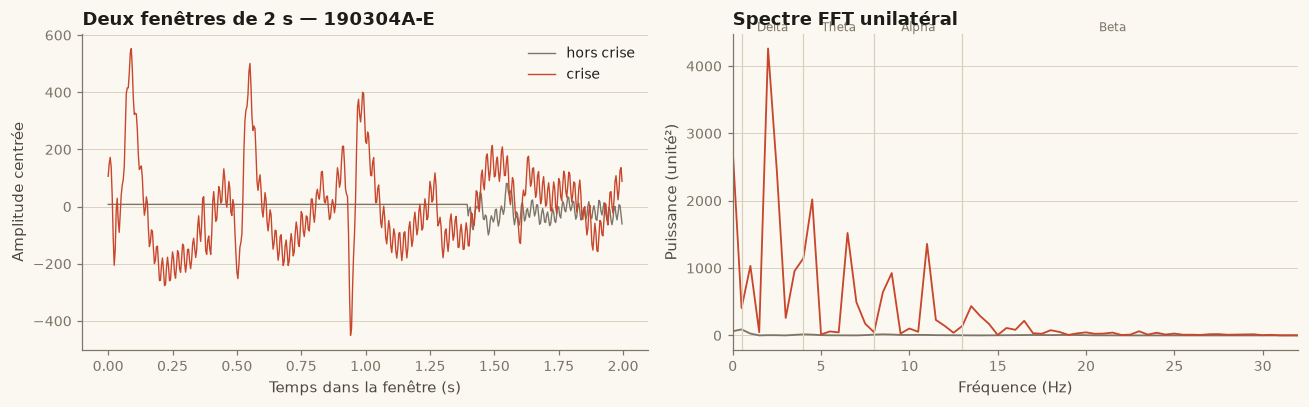

,power_delta,power_theta,power_alpha,power_beta
Classe,,,,
Hors crise,1090.980,108.823,407.043,80.355
Crise,8452.577,1747.129,1849.817,1061.372


In [10]:
presentation.spectra_plot(demo_windows, demo_labels, fs_demo, DEMO, FIGURES)
demo_features = eeg.extract_features(demo_windows, fs_demo)
display(demo_features.groupby(demo_labels)[['power_delta', 'power_theta', 'power_alpha', 'power_beta']]
        .mean().rename_axis('Classe').rename(index={0: 'Hors crise', 1: 'Crise'}))

**Q9.** Sur ce tracé, la puissance augmente dans toutes les bandes pendant la crise,
surtout en Delta (environ ×8) et en Theta : c'est la décharge de pointes-ondes
autour de 3 Hz, typique des absences.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


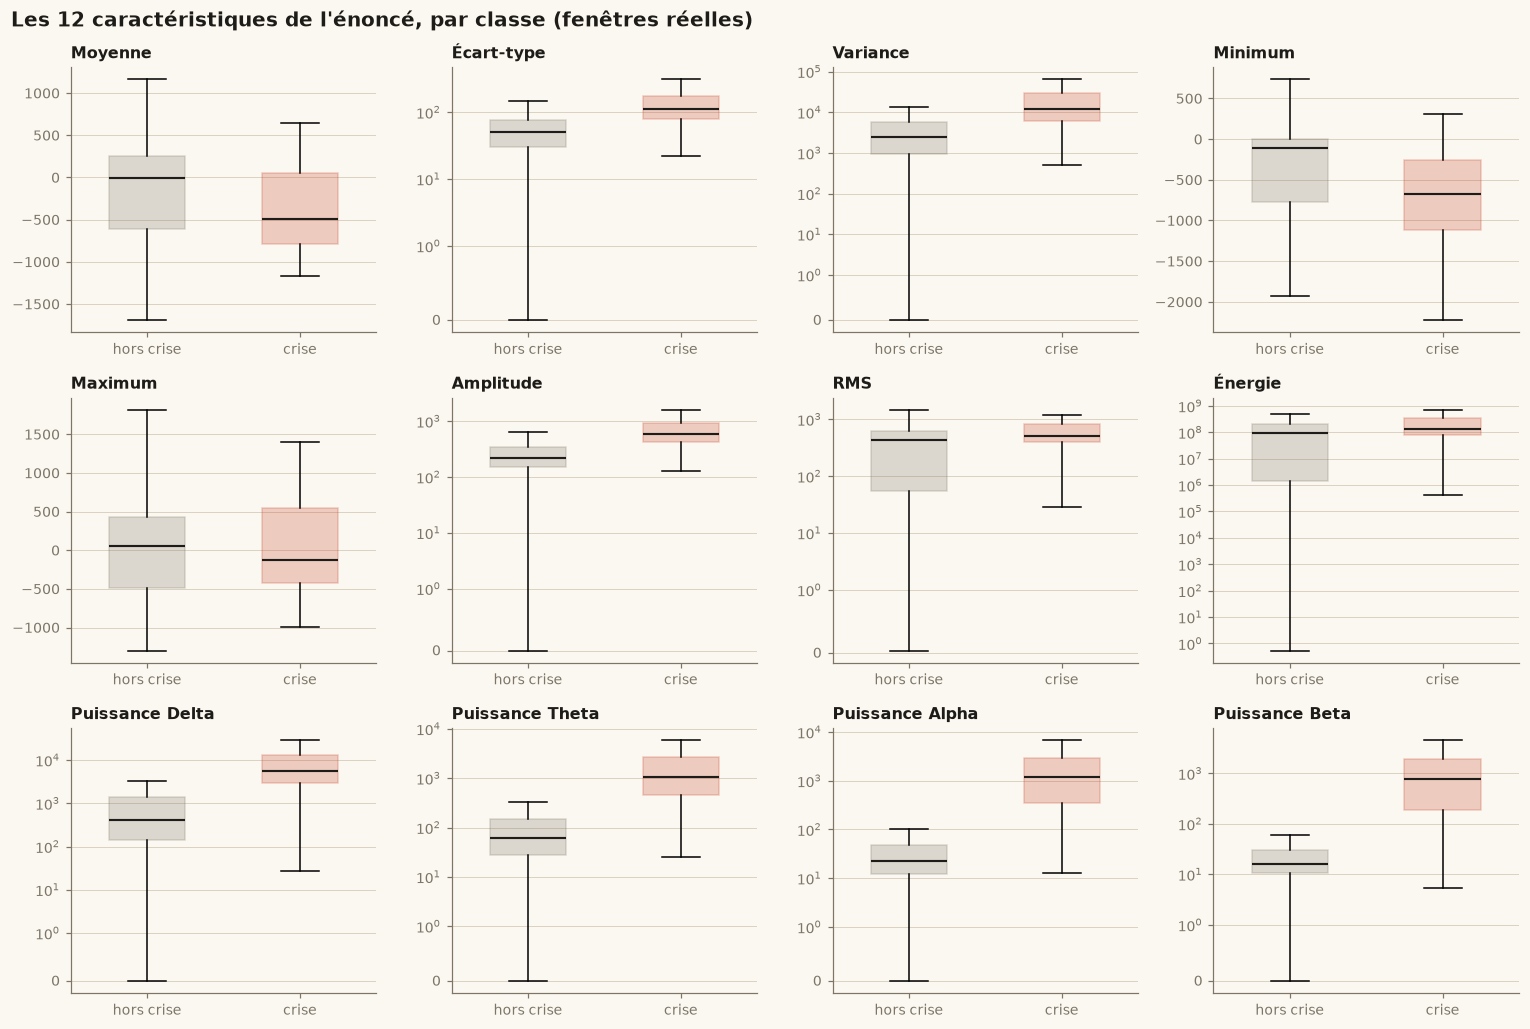

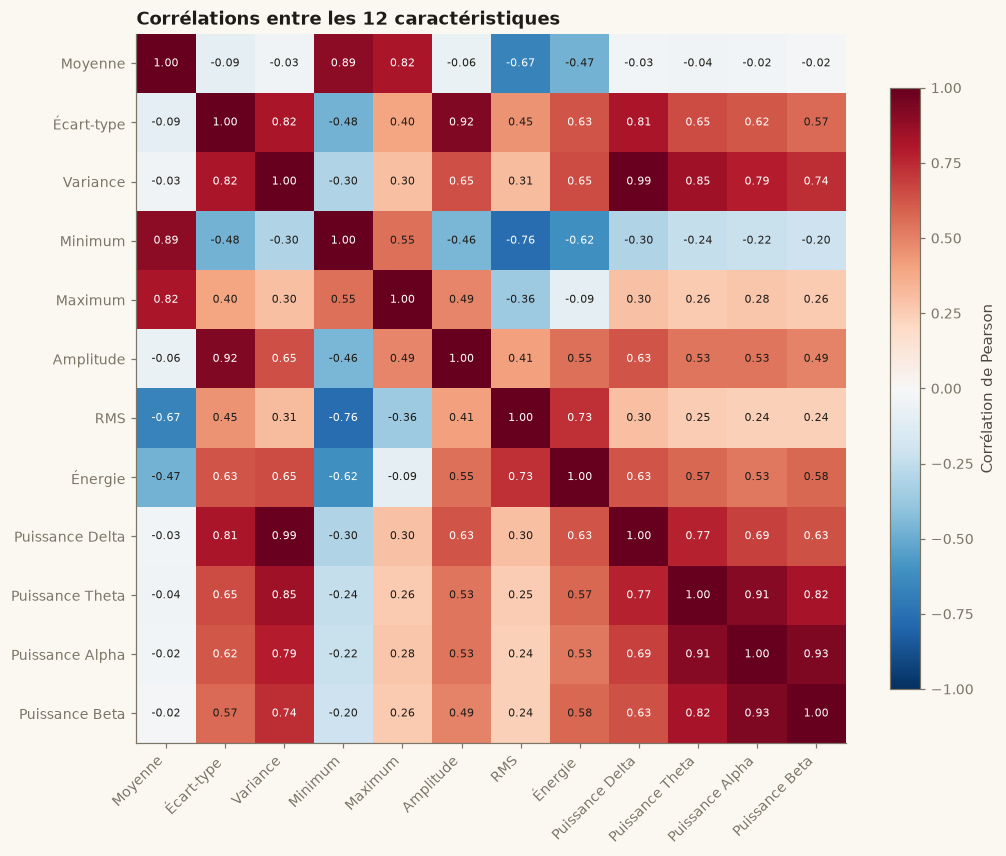

Class               Hors crise         Crise
mean        mean      -183.033      -334.951
            std        518.199       514.864
std         mean        73.746       130.606
            std        138.414        97.730
variance    mean     24596.069     26599.100
            std     395447.780    124522.177
min         mean      -339.371      -682.061
            std        593.342       490.582
max         mean       -19.353        13.261
            std        602.915       637.293
amplitude   mean       320.018       695.322
            std        564.489       456.154
rms         mean       427.538       553.286
            std        379.254       312.366
energy      mean 167227287.386 206640529.904
            std  408547286.232 202752315.310
power_delta mean     17132.612     16986.428
            std     325169.025    121272.274
power_theta mean      1392.078      2024.964
            std      34608.123      2935.276
power_alpha mean       619.190      2067.157
            std      15611.262      2348.498
power_beta  mean       770.030      1737.907
            std      23685.011      2497.109

,Variable 1,Variable 2,Corrélation
32,Variance,Puissance Delta,0.987
131,Puissance Alpha,Puissance Beta,0.932
17,Écart-type,Amplitude,0.923
118,Puissance Theta,Puissance Alpha,0.910
3,Moyenne,Minimum,0.893
33,Variance,Puissance Theta,0.850


,Écart standardisé |d| entre classes
amplitude,0.731
min,0.629
std,0.475
rms,0.362
mean,0.294
power_alpha,0.130
energy,0.122
power_beta,0.057
max,0.053
power_theta,0.026


In [11]:
feature_summary, correlation = presentation.feature_plots(frame, FIGURES)
display(feature_summary.T.rename(columns={0: 'Hors crise', 1: 'Crise'}))
correlation.to_csv(OUT / 'feature_correlations.csv')
upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
pairs = upper.stack().rename('Corrélation').reset_index()
pairs.columns = ['Variable 1', 'Variable 2', 'Corrélation']
display(pairs.loc[pairs['Corrélation'].abs() >= 0.85].sort_values('Corrélation', ascending=False))
effect = presentation.effect_sizes(frame, eeg.FEATURES).sort_values(ascending=False)
display(effect.rename('Écart standardisé |d| entre classes').to_frame())

**Q10–Q11.** Variance et écart-type, énergie et RMS sont liés par construction
(variance = écart-type², énergie = 512 × RMS²) : ils sont redondants, même si leur
corrélation de Pearson n'est pas exactement 1. Les caractéristiques qui séparent le
mieux les classes sont l'amplitude, le minimum et l'écart-type.

Deux résultats sont toutefois inquiétants :

1. **La puissance Delta ne sépare presque pas les classes** sur la cohorte
   (|d| ≈ 0), alors qu'elle est multipliée par 8 pendant la crise du tracé de
   démonstration. Ses valeurs ont une queue extrêmement lourde : l'écart-type
   dépasse 20 fois la moyenne, à cause d'artefacts.
2. **Le minimum et la moyenne figurent parmi les « meilleures » caractéristiques**,
   alors qu'une décharge à 3 Hz ne déplace pas la moyenne d'une fenêtre de 2 s.

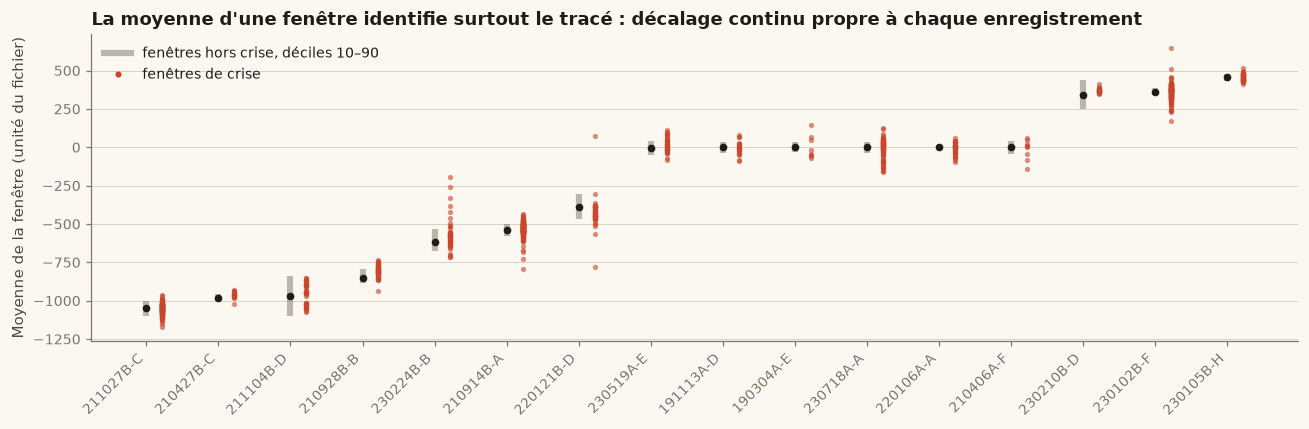

In [12]:
presentation.offset_plot(frame, FIGURES)

Le signal brut contient un **décalage continu propre à chaque enregistrement**,
de plusieurs centaines d'unités. La moyenne, le minimum et le maximum indiquent
donc surtout *de quel tracé* vient une fenêtre. Comme les tracés ont des
proportions de crises très différentes (de 0,5 % à 15,5 % des fenêtres), un modèle
peut apprendre l'identité du tracé au lieu de la crise, ce qui ne se généralise pas.

D'où un **second jeu de caractéristiques** :

- filtrage passe-haut à 0,5 Hz (Butterworth d'ordre 4, sans déphasage), qui retire le décalage et la dérive ;
- logarithmes de l'écart-type, de l'amplitude, de la longueur de ligne et des quatre puissances, contre les queues lourdes ;
- puissances relatives, part de la bande 2,5–4,5 Hz des pointes-ondes, rapport Delta / (Alpha + Beta), asymétrie, kurtosis, fréquence dominante ;
- centrage-réduction par la médiane et l'IQR **de chaque enregistrement**, sans étiquette, puis bornage à ±10.

Les 12 caractéristiques de l'énoncé restent calculées et évaluées telles quelles.

In [13]:
presentation.show_source(eeg.highpass, eeg.extract_improved_features, eeg.robust_normalize)

def highpass(signal, fs, cutoff=HIGHPASS_HZ):
    """Retire la composante continue et la dérive lente (Butterworth d'ordre 4, phase nulle)."""
    sos = butter(4, cutoff, btype="highpass", fs=fs, output="sos")
    return sosfiltfilt(sos, signal)

def extract_improved_features(windows, fs):
    """Caractéristiques sans dépendance au décalage continu, calculées sur le signal filtré."""
    eps = 1e-12
    spectrum, frequencies = one_sided_spectrum(windows, fs)
    powers = {name: band_power(spectrum, frequencies, a, b) for name, (a, b) in BANDS.items()}
    total = band_power(spectrum, frequencies, BANDS["delta"][0], BANDS["beta"][1]) + eps
    spike_wave = band_power(spectrum, frequencies, *SPIKE_WAVE_BAND)
    useful = (frequencies >= 1) & (frequencies < 30)
    peak = frequencies[useful][np.argmax(spectrum[:, useful], axis=1)]
    columns = {
        "log_std": np.log(windows.std(axis=1) + eps),
        "log_amplitude": np.log(np.ptp(windows, axis=1) + eps),
        "log_line_length": np.log(np.abs(np.diff(windows, axis=1)).mean(axis=1) + eps),
        "skewness": skew(windows, axis=1),
        "kurtosis": kurtosis(windows, axis=1),
        **{f"log_power_{name}": np.log(value + eps) for name, value in powers.items()},
        **{f"rel_{name}": value / total for name, value in powers.items()},
        "rel_spike_wave": spike_wave / total,
        "log_slow_fast_ratio": np.log(
            (powers["delta"] + eps) / (powers["alpha"] + powers["beta"] + eps)
        ),
        "peak_frequency": peak,
    }
    return pd.DataFrame(columns)[IMPROVED_FEATURES]

def robust_normalize(features):
    """Centre-réduit chaque caractéristique par la médiane et l'IQR du même enregistrement.

    Aucune étiquette n'est utilisée : seules les statistiques du tracé lui-même,
    dominé à plus de 95 % par l'activité de fond, servent de référence. Les valeurs
    sont bornées à ±10 IQR : les segments plats ou saturés ne dominent plus les distances.
    """
    median = features.median()
    iqr = features.quantile(0.75) - features.quantile(0.25)
    return ((features - median) / iqr.where(iqr > 1e-12, 1.0)).clip(-10, 10)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


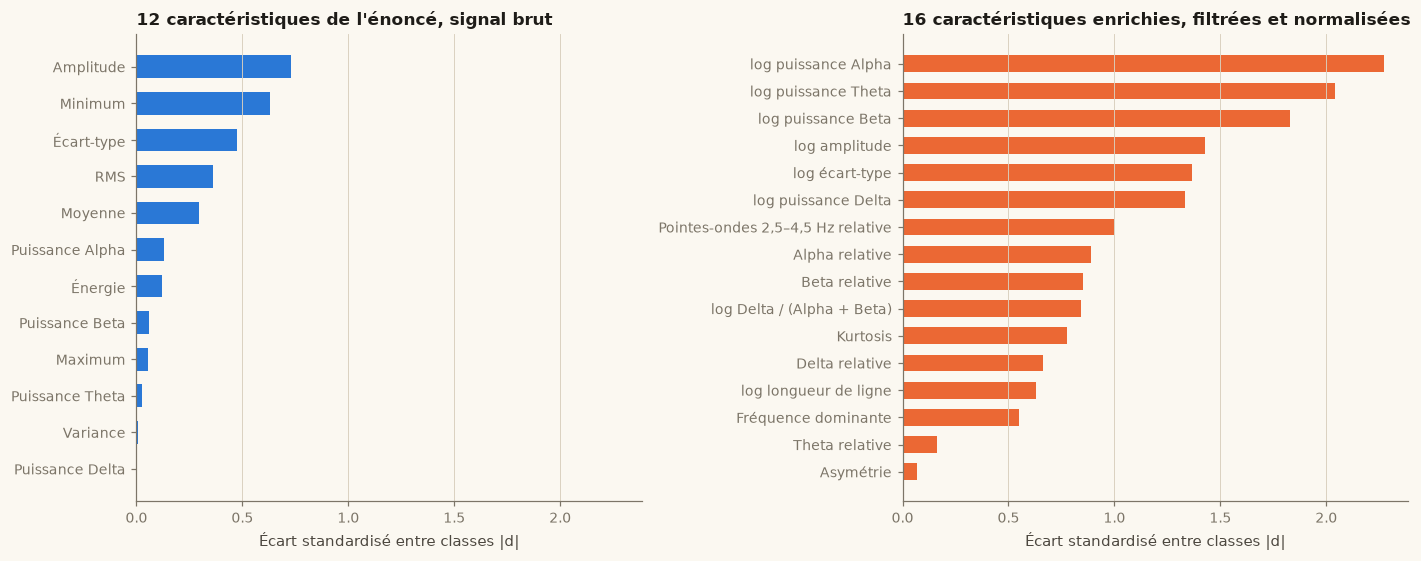

**Meilleure séparation :** 0.73 avec les 12 caractéristiques, 2.27 avec le jeu enrichi. Puissance Delta : 0.001 en brut, 1.33 en log normalisé.

In [14]:
base_effect, improved_effect = presentation.effect_comparison_plot(frame, FIGURES)
display(Markdown(
    f'**Meilleure séparation :** {base_effect.max():.2f} avec les 12 caractéristiques, '
    f'{improved_effect.max():.2f} avec le jeu enrichi. Puissance Delta : '
    f'{base_effect["power_delta"]:.3f} en brut, {improved_effect["log_power_delta"]:.2f} en log normalisé.'
))

## 7. Entraînement des modèles
**Q12.** Les fenêtres se recouvrent de 50 % et celles d'un même tracé se
ressemblent : une séparation fenêtre par fenêtre mettrait des quasi-doublons des
deux côtés. La séparation 80/20 se fait donc **par enregistrement**. Parmi 256
tirages groupés, on retient celui qui approche le mieux 80/20 et la proportion de
crises, **sans regarder aucun score**.

In [15]:
train_indices, test_indices, folds = eeg.choose_split(frame)
train_records = set(frame.iloc[train_indices].record_id)
test_records = set(frame.iloc[test_indices].record_id)
assert train_records.isdisjoint(test_records)
split_table = pd.DataFrame([
    {'Partition': name, 'Enregistrements': subset.record_id.nunique(), 'Fenêtres': len(subset),
     'Part des fenêtres (%)': 100 * len(subset) / len(frame),
     'Fenêtres crise': int(subset.Class.sum()), 'Crises (%)': 100 * subset.Class.mean()}
    for name, subset in [('Apprentissage', frame.iloc[train_indices]), ('Test réservé', frame.iloc[test_indices])]
])
display(split_table)
display(Markdown(f'**Test réservé :** {", ".join(sorted(test_records))}.'))

,Partition,Enregistrements,Fenêtres,Part des fenêtres (%),Fenêtres crise,Crises (%)
0,Apprentissage,12,18519,78.992,729,3.936
1,Test réservé,4,4925,21.008,211,4.284


**Test réservé :** 211104B-D, 220106A-A, 220121B-D, 230718A-A.

Chaque configuration est un pipeline **normalisation → rééchantillonnage éventuel →
modèle**, réajusté sur chaque pli : le rééchantillonnage ne touche jamais les
fenêtres évaluées. Hyperparamètres fixés à l'avance : arbre (profondeur 8, feuilles
d'au moins 5 fenêtres), forêt (200 arbres), KNN (5 voisins pondérés par la
distance), SVM RBF (C = 1).

Stratégies : les quatre de l'énoncé (aucune, sous-échantillonnage, duplication,
SMOTE), plus la **pondération des classes** (`class_weight="balanced"`), qui ne
s'applique pas au KNN. 2 jeux × 19 couples = **38 configurations**.

**Règle de sélection, fixée avant le calcul :** la **précision moyenne (AP)**
moyenne sur trois plis groupés de l'apprentissage. L'AP résume toute la courbe
précision-rappel sans dépendre du seuil de 0,5, que rien ne justifie avec 4 % de
positifs. Une configuration est dite *ex aequo* si son AP est à moins d'un
écart-type de la meilleure.

In [16]:
presentation.show_source(eeg.make_model)

def make_model(model_key, strategy, positive_count):
    """Encapsule normalisation, éventuel rééchantillonnage et classifieur dans un pipeline."""
    if positive_count < 2:
        raise ValueError("Trop peu de fenêtres positives pour cette comparaison.")
    if strategy == "balanced" and model_key == "knn":
        raise ValueError("Le KNN n'accepte pas de pondération des classes.")
    weight = "balanced" if strategy == "balanced" else None
    classifiers = {
        "dt": DecisionTreeClassifier(
            max_depth=8, min_samples_leaf=5, class_weight=weight, random_state=SEED
        ),
        "rf": RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            class_weight=weight,
            random_state=SEED,
            n_jobs=-1,
        ),
        "knn": KNeighborsClassifier(n_neighbors=5, weights="distance"),
        "svm": SVC(C=1.0, kernel="rbf", class_weight=weight, cache_size=1024, random_state=SEED),
    }
    samplers = {
        "original": "passthrough",
        "balanced": "passthrough",
        "under": RandomUnderSampler(random_state=SEED),
        "over": RandomOverSampler(random_state=SEED),
        "smote": SMOTE(random_state=SEED, k_neighbors=min(5, positive_count - 1)),
    }
    return Pipeline(
        [
            ("scale", StandardScaler()),
            ("sampling", samplers[strategy]),
            ("model", classifiers[model_key]),
        ]
    )

trained_experiment : relu du cache (code, données et partitions identiques).


,Configuration,AP moyenne,AP é.-t.,F1 moyen,F1 é.-t.,Rappel,Précision,Ex aequo avec le meilleur
0,Forêt aléatoire · Sans équilibrage · caractéri...,0.657,0.045,0.510,0.116,0.455,0.722,oui
1,Forêt aléatoire · Pondération des classes · ca...,0.585,0.088,0.558,0.054,0.566,0.610,
2,Forêt aléatoire · Suréchantillonnage · caracté...,0.566,0.101,0.527,0.110,0.483,0.644,
3,Forêt aléatoire · Sous-échantillonnage · carac...,0.559,0.135,0.483,0.127,0.890,0.351,
4,SVM · Sans équilibrage · caractéristiques enri...,0.538,0.060,0.337,0.149,0.228,0.737,
5,Forêt aléatoire · SMOTE · caractéristiques enr...,0.534,0.172,0.533,0.081,0.546,0.573,
6,SVM · Sous-échantillonnage · caractéristiques ...,0.506,0.156,0.460,0.090,0.832,0.332,
7,Forêt aléatoire · Sans équilibrage · caractéri...,0.491,0.183,0.389,0.177,0.407,0.510,
8,KNN · Sans équilibrage · caractéristiques enri...,0.462,0.082,0.484,0.121,0.443,0.577,
9,Forêt aléatoire · Sous-échantillonnage · carac...,0.458,0.118,0.392,0.126,0.838,0.263,


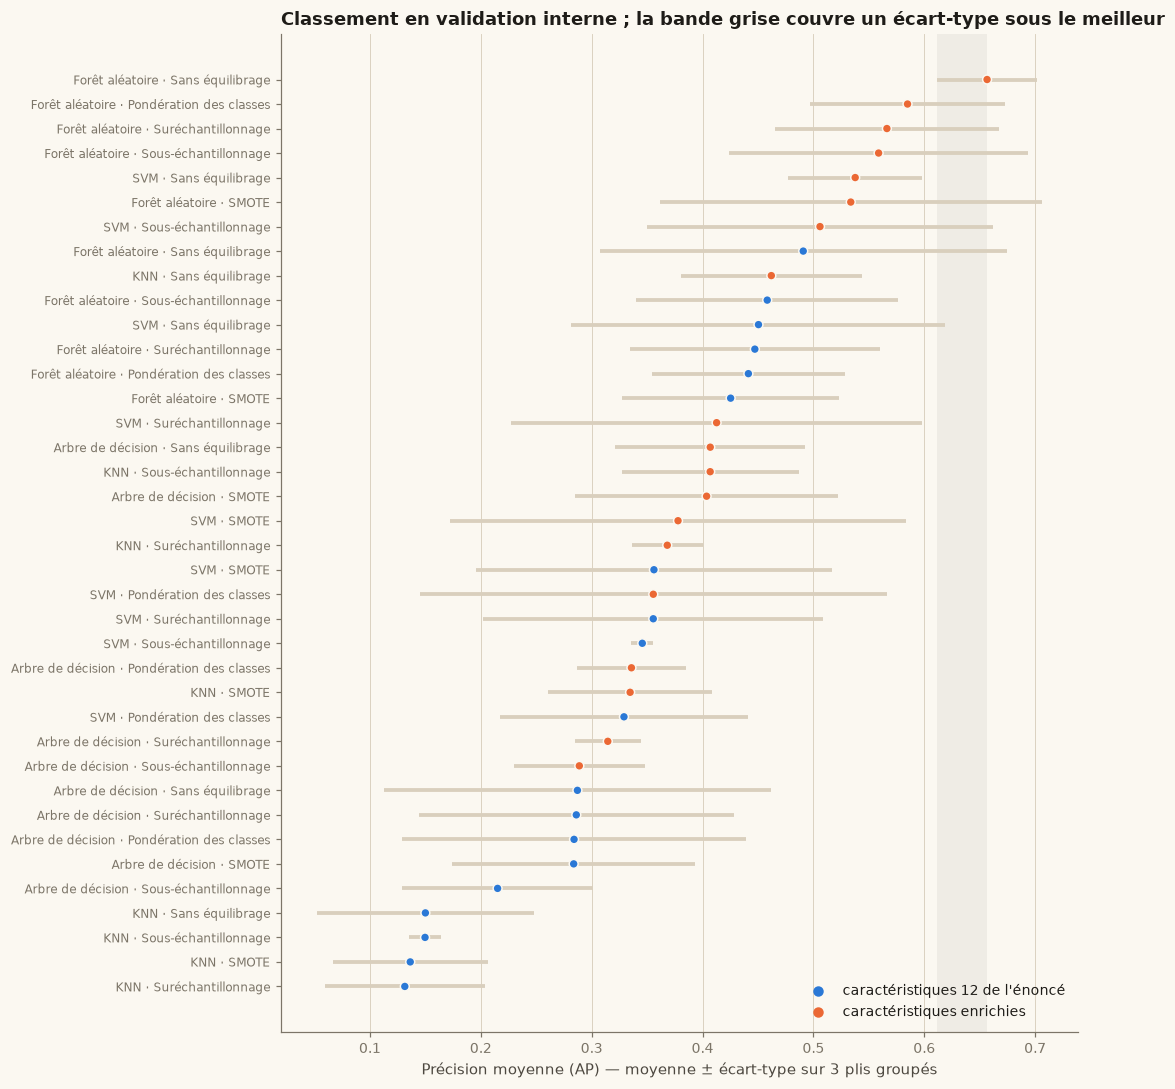

**Configuration retenue en validation interne : Forêt aléatoire · Sans équilibrage · caractéristiques enrichies.**

In [17]:
experiment = eeg.run_training(frame, train_indices, test_indices, folds, OUT, force=RETRAIN)
display(presentation.cv_table(experiment))
presentation.cv_ranking_plot(experiment, FIGURES)
best = experiment['best']
display(Markdown(f'**Configuration retenue en validation interne : {eeg.config_label(best)}.**'))

Avec les 12 caractéristiques de l'énoncé, les configurations sont très proches et
leurs écarts-types sont du même ordre que leurs différences : choisir entre elles
revient presque à tirer au sort. Avec le jeu enrichi, la forêt aléatoire se détache
nettement, quelle que soit la stratégie d'équilibrage.

## 8. Évaluation
**Q13.** Le test garde toutes ses fenêtres et son déséquilibre naturel. La classe
positive est la crise. Le seuil par défaut est utilisé ici (0,5 pour les
probabilités, 0 pour la marge du SVM).

,Accuracy,Précision,Rappel,F1,TN,FP,FN,TP
Toujours « hors crise »,0.957,0.000,0.000,0.000,4714,0,211,0


,Caractéristiques,Stratégie,Modèle,Accuracy,Précision,Rappel,F1,AP,TP,FP,FN,TN
0,12 de l'énoncé,Sans équilibrage,Arbre de décision,0.978,0.722,0.810,0.763,0.677,171,66,40,4648
1,12 de l'énoncé,Sans équilibrage,Forêt aléatoire,0.986,0.843,0.815,0.829,0.801,172,32,39,4682
2,12 de l'énoncé,Sans équilibrage,KNN,0.959,0.551,0.232,0.327,0.358,49,40,162,4674
3,12 de l'énoncé,Sans équilibrage,SVM,0.969,0.889,0.303,0.452,0.721,64,8,147,4706
4,enrichies,Sans équilibrage,Arbre de décision,0.973,0.741,0.569,0.643,0.625,120,42,91,4672
5,enrichies,Sans équilibrage,Forêt aléatoire,0.981,0.884,0.649,0.749,0.828,137,18,74,4696
6,enrichies,Sans équilibrage,KNN,0.976,0.780,0.621,0.691,0.614,131,37,80,4677
7,enrichies,Sans équilibrage,SVM,0.968,0.844,0.308,0.451,0.723,65,12,146,4702


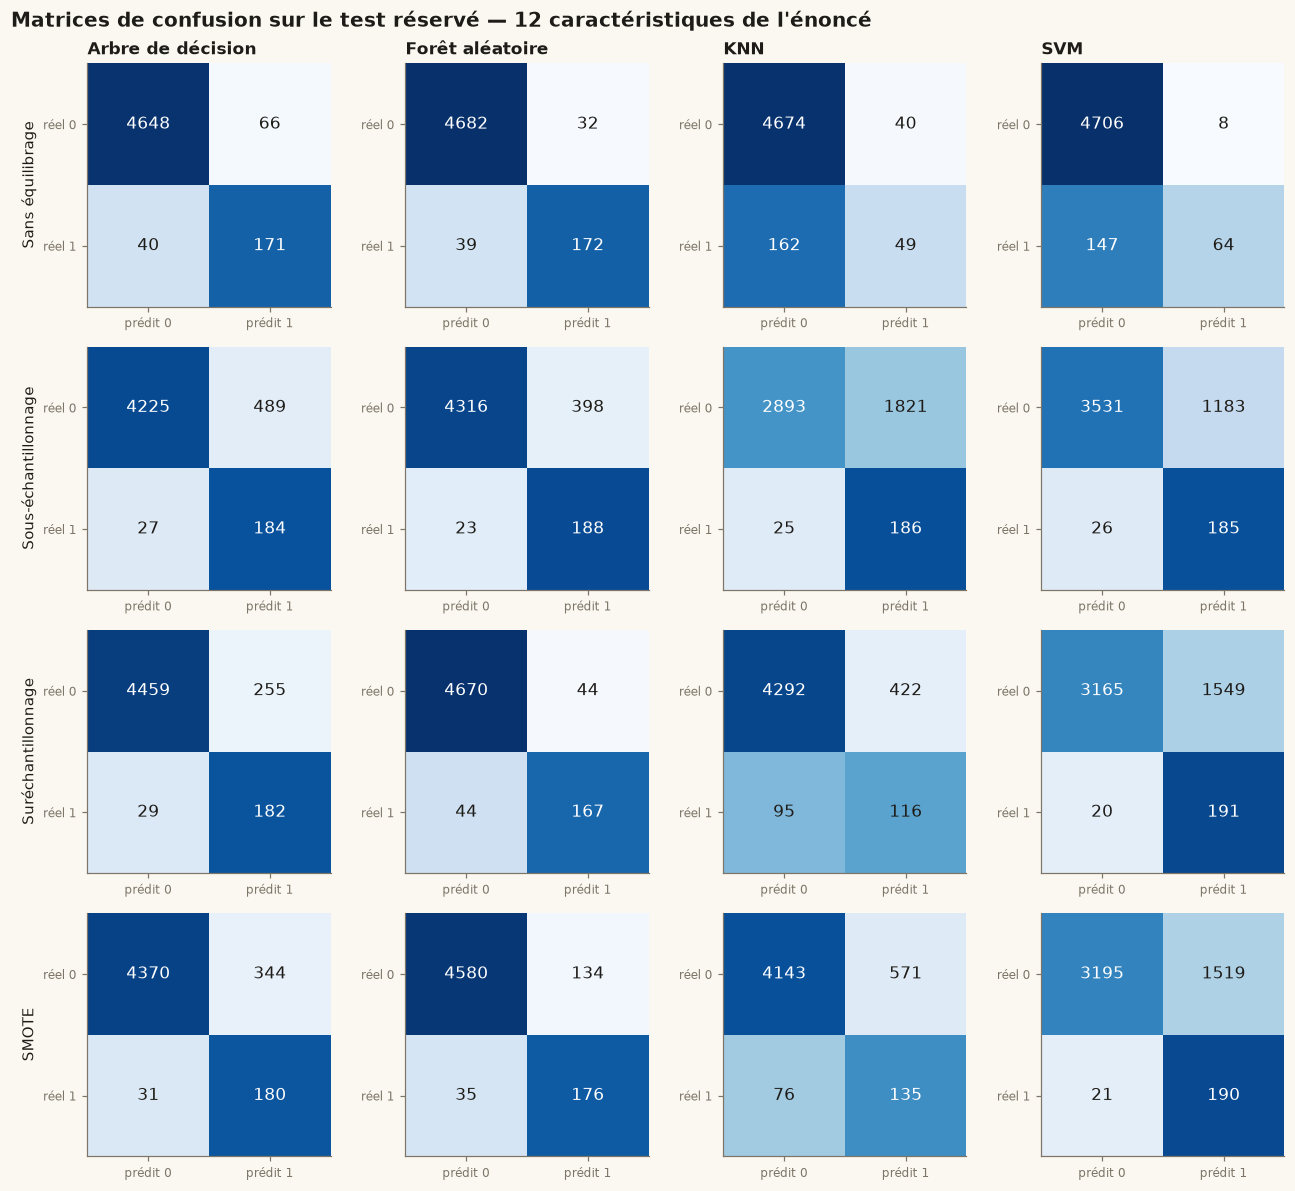

In [18]:
y_test = frame.iloc[test_indices].Class.to_numpy()
baseline = eeg.score_predictions(y_test, np.zeros(len(y_test), dtype=int))
display(pd.DataFrame([baseline], index=['Toujours « hors crise »'])
        .rename(columns={'accuracy': 'Accuracy', 'precision': 'Précision', 'recall': 'Rappel', 'f1': 'F1'}))
display(presentation.metrics_table(experiment, strategy='original'))
presentation.confusion_grid(experiment, FIGURES)

**Pourquoi l'accuracy est trompeuse.** La baseline atteint près de 96 %
d'accuracy sans détecter une seule crise. Le **rappel** compte les crises
manquées, la **précision** les fausses alertes, et le **F1** combine les deux.
Dans un contexte de détection, une crise manquée coûte plus qu'une fausse
alerte, mais trop de fausses alertes rendent l'outil inutilisable : il faut
regarder les deux.

## 9. Comparaison
Les 38 configurations sur le même test. Le choix est déjà fait (section 7) ; ce
tableau sert à comprendre, pas à choisir.

,Caractéristiques,Stratégie,Modèle,Accuracy,Précision,Rappel,F1,AP,TP,FP,FN,TN
0,12 de l'énoncé,Sans équilibrage,Arbre de décision,0.978,0.722,0.810,0.763,0.677,171,66,40,4648
1,12 de l'énoncé,Sans équilibrage,Forêt aléatoire,0.986,0.843,0.815,0.829,0.801,172,32,39,4682
2,12 de l'énoncé,Sans équilibrage,KNN,0.959,0.551,0.232,0.327,0.358,49,40,162,4674
3,12 de l'énoncé,Sans équilibrage,SVM,0.969,0.889,0.303,0.452,0.721,64,8,147,4706
4,12 de l'énoncé,Sous-échantillonnage,Arbre de décision,0.895,0.273,0.872,0.416,0.303,184,489,27,4225
5,12 de l'énoncé,Sous-échantillonnage,Forêt aléatoire,0.915,0.321,0.891,0.472,0.697,188,398,23,4316
6,12 de l'énoncé,Sous-échantillonnage,KNN,0.625,0.093,0.882,0.168,0.302,186,1821,25,2893
7,12 de l'énoncé,Sous-échantillonnage,SVM,0.755,0.135,0.877,0.234,0.483,185,1183,26,3531
8,12 de l'énoncé,Suréchantillonnage,Arbre de décision,0.942,0.416,0.863,0.562,0.633,182,255,29,4459
9,12 de l'énoncé,Suréchantillonnage,Forêt aléatoire,0.982,0.791,0.791,0.791,0.781,167,44,44,4670


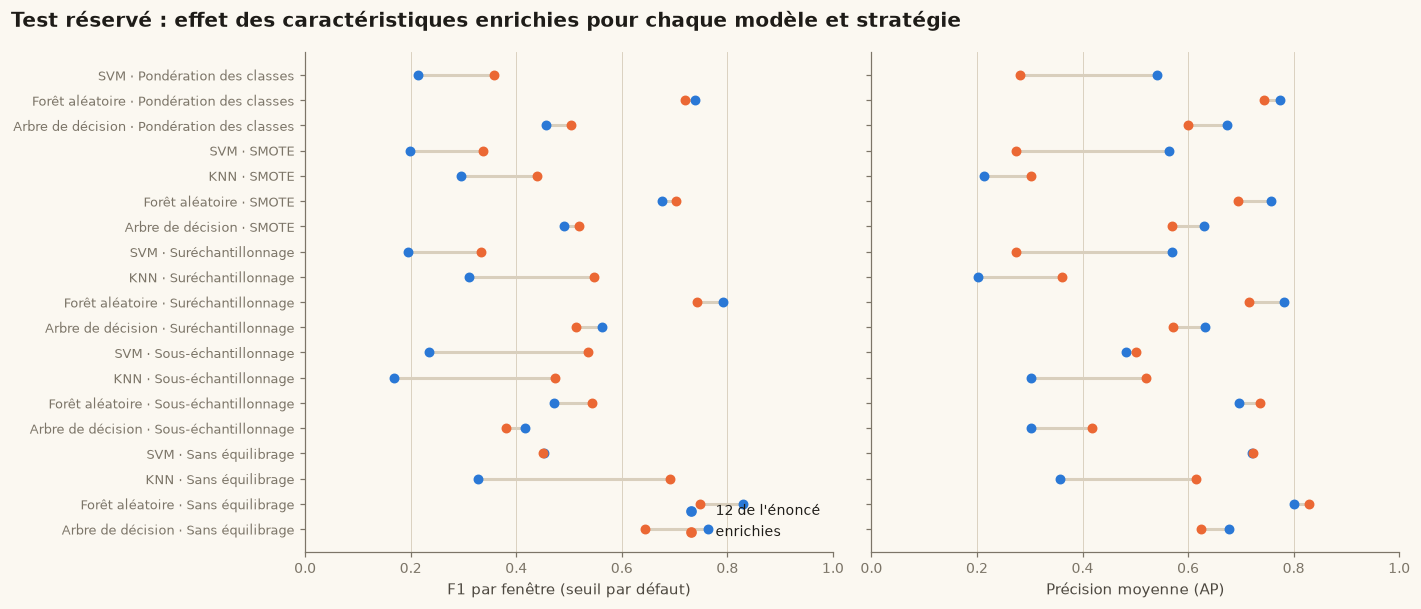

In [19]:
display(presentation.metrics_table(experiment))
presentation.comparison_plot(experiment, FIGURES)

In [20]:
res = experiment['results'].set_index('configuration')

def pick(name, metric):
    return res.loc[name, metric]

display(Markdown(
    f"**Lecture.** Au seuil par défaut, sur ces quatre tracés, le jeu enrichi n'améliore pas tout. "
    f"Il transforme le KNN (F1 {pick('base__original__knn', 'f1'):.2f} → {pick('improved__original__knn', 'f1'):.2f}) "
    f"et élève l'AP de la forêt ({pick('base__original__rf', 'average_precision'):.2f} → "
    f"{pick('improved__original__rf', 'average_precision'):.2f}), mais la forêt sur les 12 caractéristiques garde "
    f"le meilleur F1 brut ({pick('base__original__rf', 'f1'):.2f} contre {pick('improved__original__rf', 'f1'):.2f}). "
    "Avec 4 tracés, ce classement est fragile : la section 12 le vérifie sur les 16 tracés. "
    "Les stratégies d'équilibrage déplacent le compromis (plus de rappel, moins de précision) sans ajouter d'information."
))

**Lecture.** Au seuil par défaut, sur ces quatre tracés, le jeu enrichi n'améliore pas tout. Il transforme le KNN (F1 0.33 → 0.69) et élève l'AP de la forêt (0.80 → 0.83), mais la forêt sur les 12 caractéristiques garde le meilleur F1 brut (0.83 contre 0.75). Avec 4 tracés, ce classement est fragile : la section 12 le vérifie sur les 16 tracés. Les stratégies d'équilibrage déplacent le compromis (plus de rappel, moins de précision) sans ajouter d'information.

## 10. Détection temporelle
**Q14.** Les fenêtres positives qui se touchent ou se recouvrent forment un
épisode `[début de la première fenêtre ; fin de la dernière]`. Un épisode prédit
est apparié à une crise annotée si leur **IoU** (intersection / union) atteint
**0,3**, avec un appariement un à un.

La sortie brute du classifieur produit beaucoup d'épisodes d'une ou deux fenêtres
isolées. Trois réglages les filtrent : un **lissage** du score sur 1, 3 ou 5
fenêtres, un **seuil**, et une **durée minimale** de 1 à 5 fenêtres consécutives.
Ils maximisent le F1 événementiel sur les **prédictions hors pli de
l'apprentissage**, puis sont figés avant d'être appliqués au test.

In [21]:
presentation.show_source(eeg.smooth_scores, eeg.drop_short_runs, eeg.intervals_from_labels)

def smooth_scores(scores, width):
    """Moyenne glissante centrée sur `width` fenêtres, bords normalisés."""
    scores = np.asarray(scores, dtype=float)
    if width <= 1:
        return scores
    kernel = np.ones(width)
    return np.convolve(scores, kernel, mode="same") / np.convolve(
        np.ones(len(scores)), kernel, mode="same"
    )

def drop_short_runs(labels, min_windows):
    """Supprime les suites de fenêtres positives plus courtes que `min_windows`."""
    labels = np.asarray(labels, dtype=bool).copy()
    if min_windows <= 1 or not labels.any():
        return labels
    edges = np.flatnonzero(np.diff(np.r_[0, labels.astype(np.int8), 0]))
    for start, stop in zip(edges[::2], edges[1::2], strict=True):
        if stop - start < min_windows:
            labels[start:stop] = False
    return labels

def intervals_from_labels(starts, ends, labels):
    """Version vectorisée de `reconstruct_intervals` pour des fenêtres triées de même durée."""
    edges = np.flatnonzero(np.diff(np.r_[0, np.asarray(labels, dtype=np.int8), 0]))
    intervals = []
    for a, b in zip(edges[::2], edges[1::2], strict=True):
        start, end = float(starts[a]), float(ends[b - 1])
        if intervals and start <= intervals[-1][1]:
            intervals[-1] = (intervals[-1][0], max(intervals[-1][1], end))
        else:
            intervals.append((start, end))
    return intervals

**Réglages retenus hors pli :** lissage sur 5 fenêtre(s), seuil 0.248, au moins 5 fenêtre(s) consécutive(s).

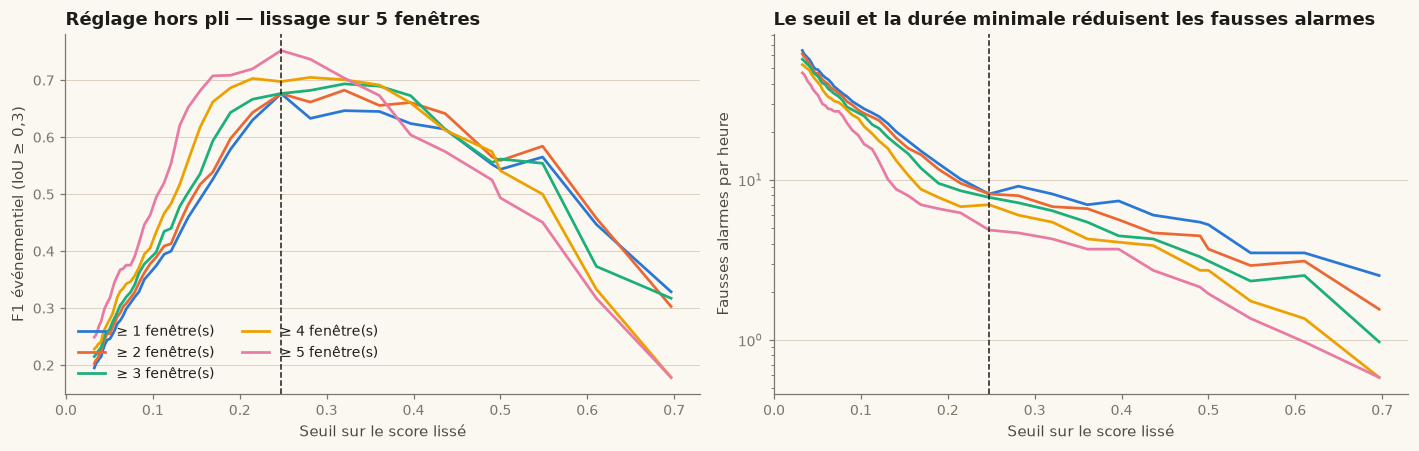

,Données,Sortie,Précision fen.,Rappel fen.,F1 fen.,Crises retrouvées,Crises manquées,Fausses alarmes,Rappel év.,Précision év.,Fausses alarmes / h
0,Validation interne,Sortie brute,0.662,0.425,0.518,35,13,84,0.729,0.294,16.319
1,Validation interne,Post-traitement,0.641,0.753,0.693,44,4,25,0.917,0.638,4.857
2,Test réservé,Sortie brute,0.884,0.649,0.749,12,5,7,0.706,0.632,5.113
3,Test réservé,Post-traitement,0.842,0.834,0.838,14,3,2,0.824,0.875,1.461


In [22]:
temporal = eeg.temporal_analysis(frame, events, experiment, OUT)
params = temporal['params']
display(Markdown(f'**Réglages retenus hors pli :** lissage sur {params["smoothing"]} fenêtre(s), '
                 f'seuil {params["threshold"]:.3f}, au moins {params["min_windows"]} fenêtre(s) consécutive(s).'))
presentation.postprocessing_plot(temporal, FIGURES)
display(presentation.comparison_table(temporal))

,Enregistrement,Résultat,Début réel (s),Fin réelle (s),Début prédit (s),Fin prédite (s),IoU
0,211104B-D,FN,253.000,259.000,NaN,NaN,0.000
1,211104B-D,TP,384.000,392.000,386.000,392.000,0.750
2,211104B-D,TP,555.000,565.000,557.000,565.000,0.800
3,211104B-D,FN,806.000,814.000,NaN,NaN,0.000
4,211104B-D,FN,896.000,904.000,NaN,NaN,0.000
5,211104B-D,FP,NaN,NaN,53.000,61.000,0.000
6,220106A-A,TP,335.000,354.000,335.000,356.000,0.905
7,220106A-A,TP,1151.000,1169.000,1150.000,1170.000,0.900
8,220121B-D,TP,105.000,120.000,104.000,121.000,0.882
9,220121B-D,TP,330.000,348.000,329.000,348.000,0.947


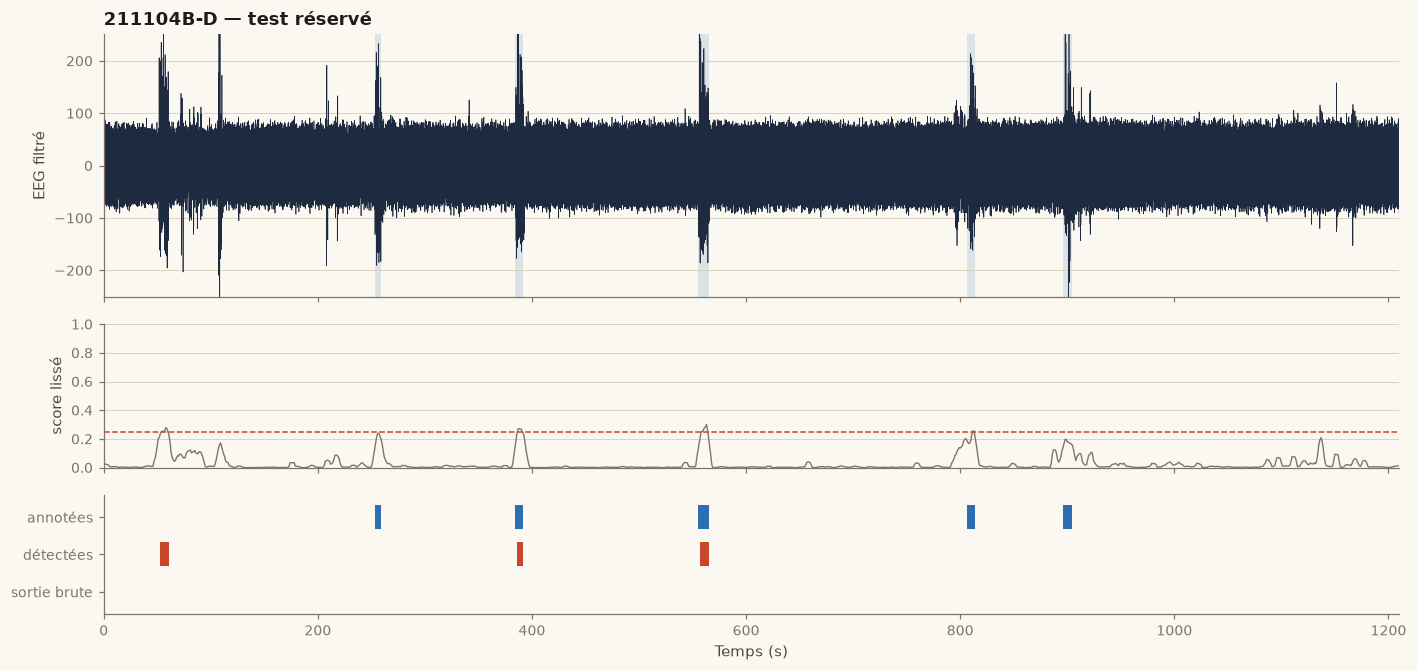

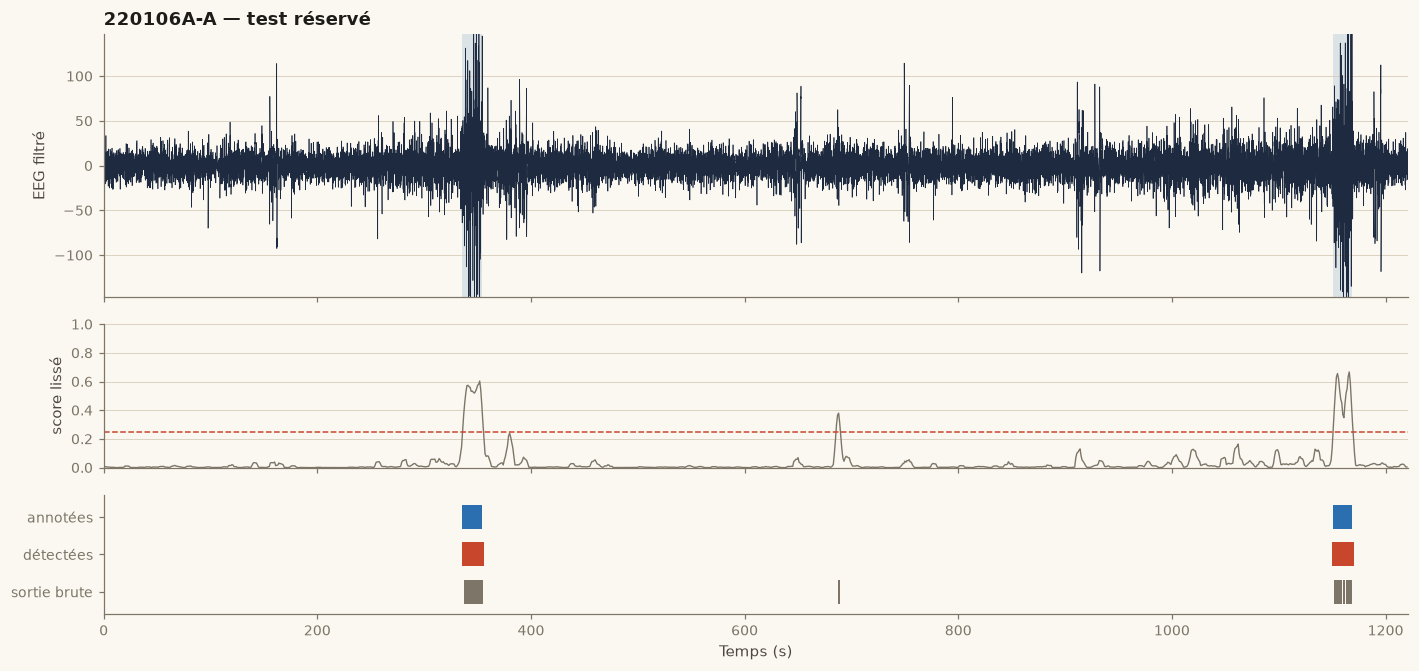

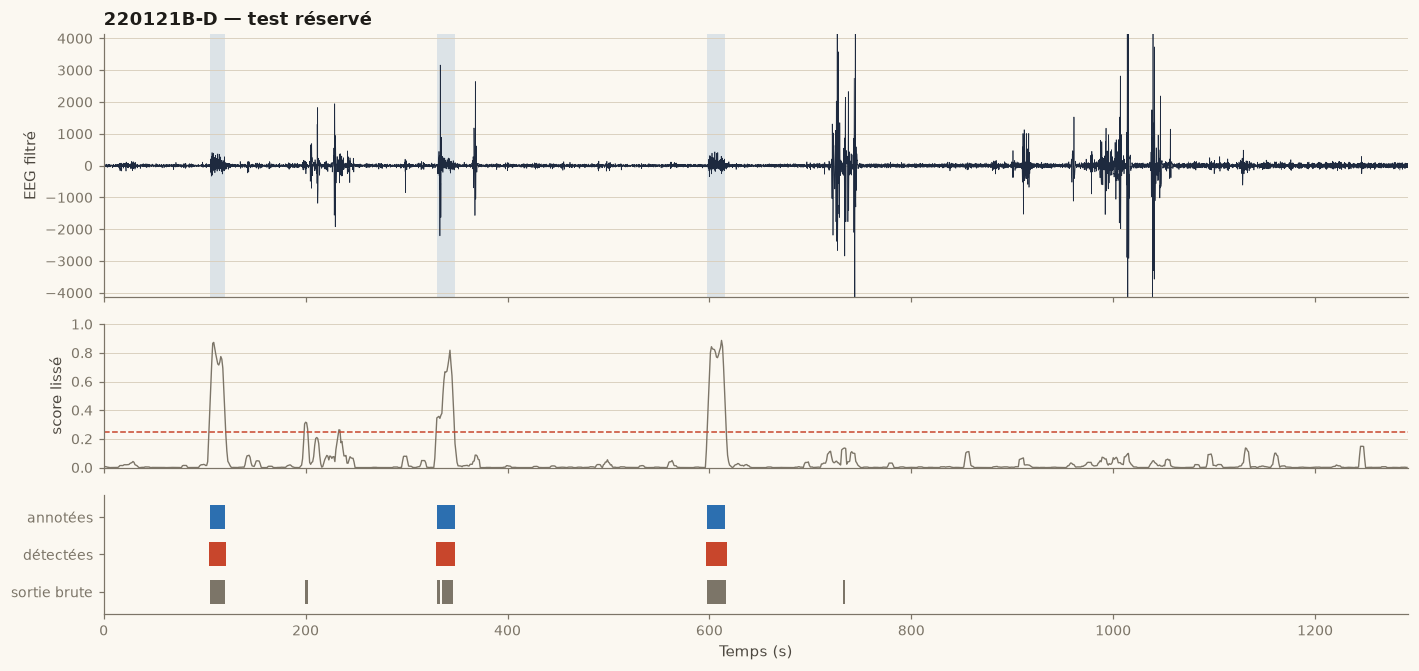

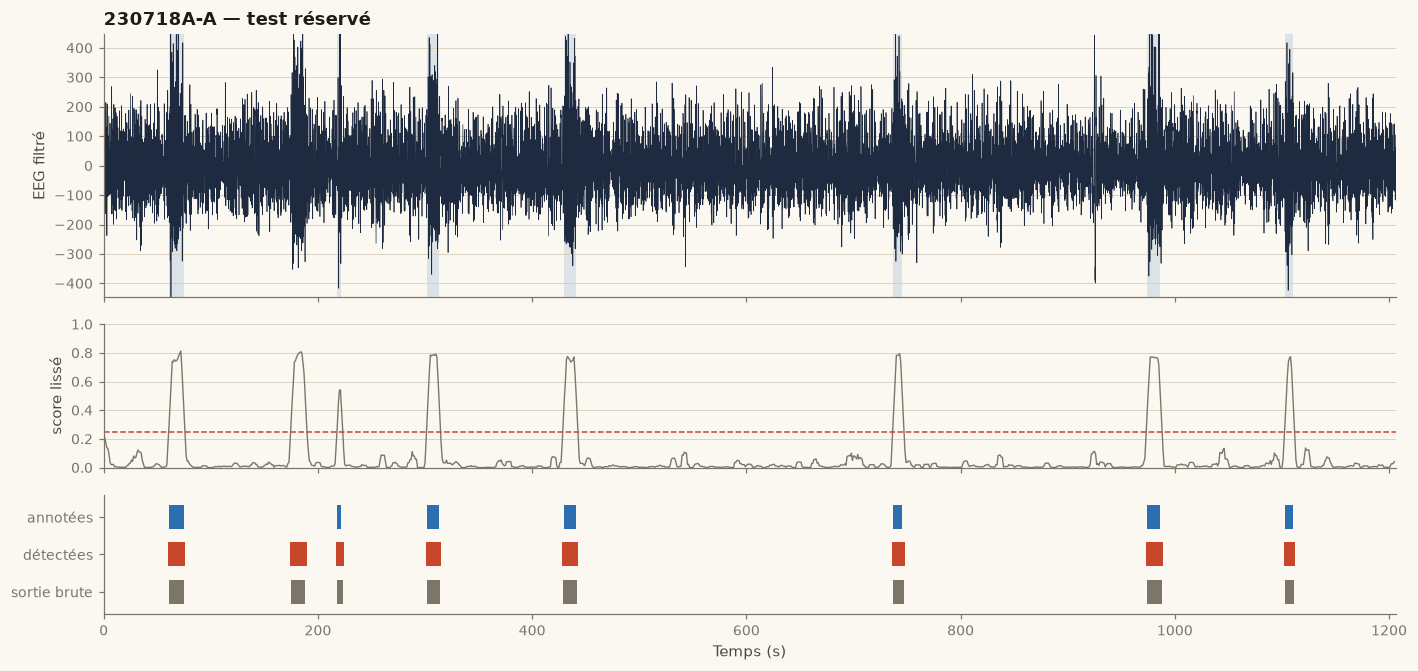

In [23]:
display(temporal['details'].sort_values(['record_id', 'true_start_s', 'pred_start_s']).rename(columns={
    'record_id': 'Enregistrement', 'status': 'Résultat', 'true_start_s': 'Début réel (s)',
    'true_end_s': 'Fin réelle (s)', 'pred_start_s': 'Début prédit (s)', 'pred_end_s': 'Fin prédite (s)'
}))
presentation.temporal_plots(ROOT, events, validation, temporal, FIGURES)

## 11. Analyse des erreurs
Fenêtres et épisodes sont comptés séparément : une crise de 20 s compte une
vingtaine de fenêtres mais un seul épisode.

In [24]:
display(temporal['windows'].rename(columns={'record_id': 'Enregistrement', 'accuracy': 'Accuracy',
                                           'precision': 'Précision', 'recall': 'Rappel', 'f1': 'F1'}))
display(temporal['events'].rename(columns={
    'record_id': 'Enregistrement', 'true_events': 'Crises annotées', 'raw_predicted_events': 'Épisodes bruts',
    'predicted_events': 'Épisodes post-traités', 'precision': 'Précision', 'recall': 'Rappel', 'f1': 'F1',
    'false_alarms_per_hour': 'Fausses alarmes / h'}))
details = temporal['details'].assign(duration=lambda d: d.true_end_s - d.true_start_s,
                                     predicted=lambda d: d.pred_end_s - d.pred_start_s)
missed = details[details.status == 'FN']
found = details[details.status == 'TP']
false = details[details.status == 'FP']
raw = temporal['events'].set_index('record_id').raw_predicted_events
lines = [f"**{len(missed)} crise(s) manquée(s)** sur {len(missed) + len(found)}, "
         f"{len(false)} fausse(s) alarme(s)."]
if len(missed):
    by_record = missed.groupby('record_id').duration.agg(['count', 'min', 'max'])
    lines.append('Crises manquées par tracé : ' + ' ; '.join(
        f"{rid} : {int(row['count'])} ({row['min']:.0f}–{row['max']:.0f} s, "
        f"{int(raw[rid])} épisode(s) en sortie brute)" for rid, row in by_record.iterrows()) + '.')
    lines.append(f"Plus courte crise retrouvée : {found.duration.min():.0f} s. "
                 f"Plus longue crise manquée : {missed.duration.max():.0f} s.")
if len(false):
    lines.append('Fausses alarmes : ' + ' ; '.join(
        f"{r.record_id} à {r.pred_start_s:.0f}–{r.pred_end_s:.0f} s ({r.predicted:.0f} s)" for r in false.itertuples()) + '.')
display(Markdown(' '.join(lines)))

,Enregistrement,Accuracy,Précision,Rappel,F1,TN,FP,FN,TP
0,211104B-D,0.967,0.632,0.267,0.375,1157,7,33,12
1,220106A-A,0.998,0.974,0.974,0.974,1180,1,1,38
2,220121B-D,0.998,0.981,0.981,0.981,1237,1,1,52
3,230718A-A,0.980,0.755,1.000,0.860,1107,24,0,74


,Enregistrement,Crises annotées,Épisodes bruts,Épisodes post-traités,TP,FP,FN,Précision,Rappel,F1,Fausses alarmes / h
0,211104B-D,5,0,3,2,1,3,0.667,0.400,0.500,2.975
1,220106A-A,2,5,2,2,0,0,1.000,1.000,1.000,0.000
2,220121B-D,3,6,3,3,0,0,1.000,1.000,1.000,0.000
3,230718A-A,7,8,8,7,1,0,0.875,1.000,0.933,2.985


**3 crise(s) manquée(s)** sur 17, 2 fausse(s) alarme(s). Crises manquées par tracé : 211104B-D : 3 (6–8 s, 0 épisode(s) en sortie brute). Plus courte crise retrouvée : 4 s. Plus longue crise manquée : 8 s. Fausses alarmes : 211104B-D à 53–61 s (8 s) ; 230718A-A à 174–190 s (16 s).

Les omissions sont concentrées dans un seul tracé, où les scores restent bas
même pendant les crises : le modèle y sous-estime l'activité de crise, ce qui
tient davantage à l'enregistrement qu'à la durée des crises, puisqu'une crise
plus courte est retrouvée ailleurs. Les fausses alarmes durent aussi longtemps que des
crises réelles ; seule une relecture du tracé dirait s'il s'agit d'artefacts ou
d'absences non annotées. La validation « un enregistrement exclu » (section 12)
montre la même hétérogénéité d'un tracé à l'autre.

## 12. Améliorations
**Rééchantillonnage.** Le sous-échantillonnage garde toutes les fenêtres de
crise de l'apprentissage et autant de fenêtres normales tirées au hasard. Le
suréchantillonnage garde les normales et multiplie les crises, par duplication
ou par SMOTE (interpolation entre crises voisines dans l'espace des
caractéristiques). La règle exacte est `N_normales_retenues = N_crises`.

In [25]:
resampling = experiment['results'].drop_duplicates('strategy')[[
    'strategy', 'train_positive_before', 'train_negative_before',
    'train_positive_after', 'train_negative_after']].copy()
resampling.strategy = resampling.strategy.map(eeg.STRATEGIES)
resampling.columns = ['Stratégie', 'Crises avant', 'Normales avant', 'Crises après', 'Normales après']
display(resampling)
results = experiment['results']
reference = results.loc[results.strategy == 'original']
before_after = results.merge(reference[['feature_set', 'model', 'precision', 'recall', 'f1']],
                             on=['feature_set', 'model'], suffixes=('', '_ref'))
for metric in ('precision', 'recall', 'f1'):
    before_after['Δ ' + metric] = before_after[metric] - before_after[metric + '_ref']
before_after = before_after.loc[before_after.strategy != 'original']
pivot = before_after.pivot_table(index=['feature_set', 'strategy'], values=['Δ precision', 'Δ recall', 'Δ f1'],
                                 aggfunc='mean').rename(index=eeg.FEATURE_SET_LABELS, level=0).rename(
                                 index=eeg.STRATEGIES, level=1)
display(Markdown('**Variation moyenne sur les quatre modèles, par rapport à « sans équilibrage » (test).**'))
display(pivot[['Δ precision', 'Δ recall', 'Δ f1']])

,Stratégie,Crises avant,Normales avant,Crises après,Normales après
0,Sans équilibrage,729,17790,729,17790
4,Sous-échantillonnage,729,17790,729,729
8,Suréchantillonnage,729,17790,17790,17790
12,SMOTE,729,17790,17790,17790
16,Pondération des classes,729,17790,729,17790


**Variation moyenne sur les quatre modèles, par rapport à « sans équilibrage » (test).**

Δ precision  Δ recall   Δ f1
feature_set    strategy                                             
12 de l'énoncé Pondération des classes       -0.452     0.234 -0.212
               Suréchantillonnage            -0.368     0.237 -0.128
               SMOTE                         -0.448     0.267 -0.178
               Sous-échantillonnage          -0.545     0.340 -0.270
enrichies      Pondération des classes       -0.337     0.101 -0.088
               Suréchantillonnage            -0.321     0.086 -0.099
               SMOTE                         -0.364     0.070 -0.134
               Sous-échantillonnage          -0.466     0.284 -0.151

Le rééchantillonnage augmente le rappel et fait chuter la précision : il déplace
le seuil implicite du modèle sans lui apprendre quoi que ce soit de nouveau. Ce
déplacement s'obtient plus proprement en réglant le seuil du score, comme en
section 10. Les gains mesurés dans ce projet, confirmés ci-dessous sur les
16 tracés, viennent de trois sources :

1. **Les caractéristiques** (section 6) : retirer le décalage continu et passer en log.
2. **La sélection par AP** plutôt que par F1 au seuil 0,5.
3. **Le raisonnement par épisodes** (section 10) : lissage, seuil et durée minimale.

**Validation « un enregistrement exclu ».** Le test ne compte que 4 tracés. Pour
mesurer la variabilité, la configuration retenue et trois références fixées à
l'avance (l'ancien choix arbre + SMOTE, la forêt sur les 12 caractéristiques, la
forêt enrichie) sont réévaluées 16 fois, chaque tracé étant exclu à tour de rôle.
À chaque itération, le post-traitement est réglé sur les prédictions hors pli des
15 autres tracés.

loro : relu du cache (code, données et partitions identiques).


,Configuration,Sortie,F1 fen. médiane,F1 fen. Q1–Q3,F1 fen. poolé,Rappel év.,Précision év.,Fausses alarmes / h
0,Forêt aléatoire · Sans équilibrage · caractéri...,Sortie brute,0.612,0.34–0.77,0.576,0.723,0.373,12.123
1,Forêt aléatoire · Sans équilibrage · caractéri...,Post-traitement,0.785,0.65–0.92,0.697,0.846,0.671,4.143
2,Arbre de décision · SMOTE · caractéristiques 1...,Sortie brute,0.487,0.31–0.58,0.349,0.892,0.081,101.432
3,Arbre de décision · SMOTE · caractéristiques 1...,Post-traitement,0.781,0.20–0.86,0.365,0.569,0.330,11.509
4,Forêt aléatoire · Sans équilibrage · caractéri...,Sortie brute,0.716,0.40–0.86,0.475,0.815,0.214,29.923
5,Forêt aléatoire · Sans équilibrage · caractéri...,Post-traitement,0.752,0.02–0.82,0.377,0.538,0.347,10.128


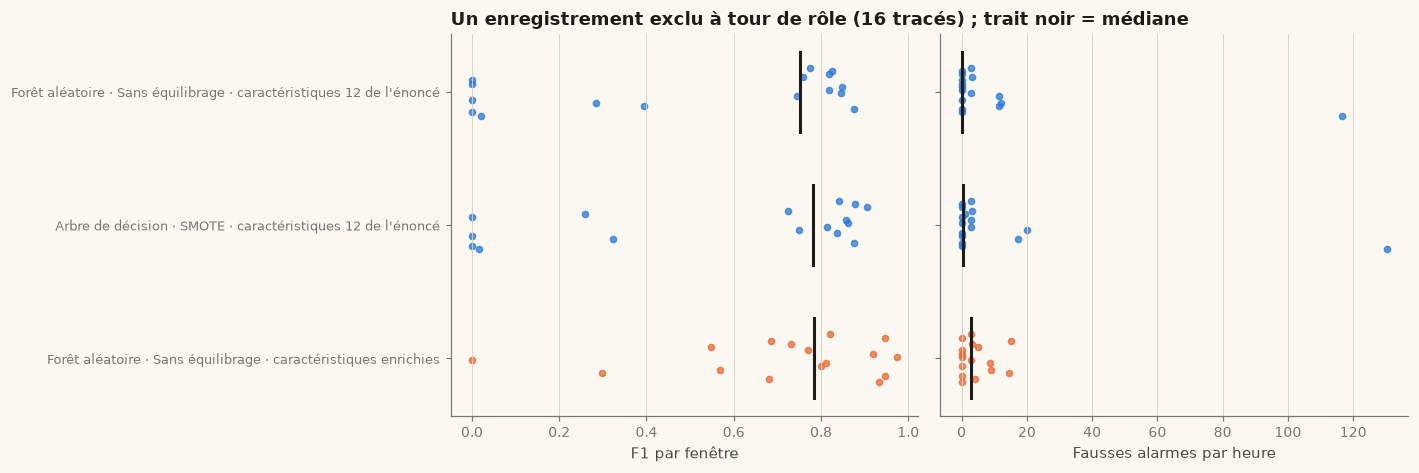

In [26]:
loro = eeg.leave_one_record_out(frame, events, eeg.loro_shortlist(best), OUT, force=RETRAIN)
display(presentation.loro_table(loro))
presentation.loro_plot(loro, FIGURES)

### Conclusion et limites
Avec un seul canal et une forêt aléatoire, la chaîne retrouve la grande majorité
des crises de cette cohorte avec quelques fausses alarmes par heure, à condition
de retirer le décalage continu, d'utiliser des caractéristiques indépendantes de
l'échelle de chaque tracé et de raisonner en épisodes. L'équilibrage des classes
pèse peu face à ces trois choix.

**Limites.** 16 enregistrements sans identifiant patient fiable ; un seul canal ;
annotations sans double relecture ; hyperparamètres non optimisés ; la normalisation
par enregistrement suppose un tracé long, dominé par l'activité de fond. Les
chiffres LORO, plus prudents que ceux du test réservé, sont ceux à retenir.

In [27]:
report_path = presentation.write_report(ROOT, cohort, events, counts, frame, experiment, temporal, loro, gaps)
assert train_records.isdisjoint(test_records)
assert len(experiment['results']) == 38 and len(experiment['cv']) == 38 * 3
assert validation[['source_values_match', 'source_names_match', 'source_times_match']].all().all()
display(Markdown(f'**Rapport régénéré :** `{report_path.relative_to(ROOT)}`, figures dans `reports/figures/`.'))

**Rapport régénéré :** `reports/RAPPORT_FINAL_EEG.md`, figures dans `reports/figures/`.